In [13]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal, List, Sequence, Annotated

Exemple 1 : routage de tickets d’assistance


In [15]:

class TicketState(TypedDict):
    ticket_id: str
    severity: int
    waiting_hours: int
    decision: Literal["standard", "urgent"]
    result: str


In [16]:

def analyze_ticket(state: TicketState) -> TicketState:
    # Un ticket est urgent si sa gravité est élevée ou s'il attend depuis 48 h.
    if state["severity"] >= 4 or state["waiting_hours"] >= 48:
        state["decision"] = "urgent"
    else:
        state["decision"] = "standard"

    print(f"Le ticket {state['ticket_id']} a été analysé.")
    return state


In [17]:

def standard_support_process(state: TicketState) -> TicketState:
    state["result"] = f"Le ticket {state['ticket_id']} suit le traitement standard."
    print(state["result"])
    return state


In [18]:

def urgent_support_process(state: TicketState) -> TicketState:
    state["result"] = f"Le ticket {state['ticket_id']} est transmis en priorité."
    print(state["result"])
    return state


In [19]:

def router(state: TicketState) -> str:
    return state["decision"]


In [20]:

workflow = StateGraph(TicketState)
workflow.add_node("analyze_ticket", analyze_ticket)
workflow.add_node("standard_support_node", standard_support_process)
workflow.add_node("urgent_support_node", urgent_support_process)

workflow.add_edge(START, "analyze_ticket")
workflow.add_conditional_edges(
    "analyze_ticket",
    router,
    {
        "standard": "standard_support_node",
        "urgent": "urgent_support_node",
    },
)
workflow.add_edge("standard_support_node", END)
workflow.add_edge("urgent_support_node", END)

graph = workflow.compile()


In [21]:
from IPython.display import Image

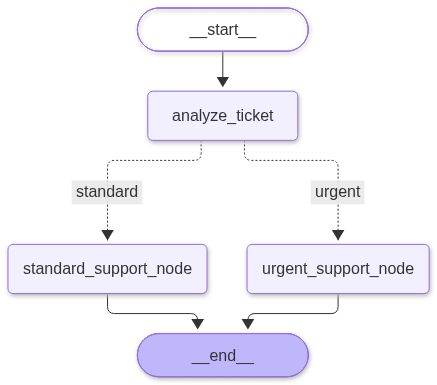

In [22]:
display(Image(graph.get_graph().draw_mermaid_png()))

Test du routage des tickets


In [23]:

result = graph.invoke({
    "ticket_id": "TCK-1042",
    "severity": 5,
    "waiting_hours": 8,
})
result


Le ticket TCK-1042 a été analysé.
Le ticket TCK-1042 est transmis en priorité.


{'ticket_id': 'TCK-1042',
 'severity': 5,
 'waiting_hours': 8,
 'decision': 'urgent',
 'result': 'Le ticket TCK-1042 est transmis en priorité.'}

Create agent

agent_tool

In [24]:

import os
from dotenv import load_dotenv
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage
from langgraph.graph import add_messages
from langgraph.prebuilt import ToolNode
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv(dotenv_path=".env", override=True)
gemini_api_key = os.getenv("GEMINI_API_KEY")
if not gemini_api_key:
    raise RuntimeError("GEMINI_API_KEY est absente du fichier .env de TP6.")


In [25]:
@tool
def somme(a:int, b:int):
    """Add two integers a and b 
    """
    print(f"Adding {a} to {b}")
    return a+b

@tool
def produit(a:int, b:int):
    """Multiply two integers a and b 
    """
    print(f"Multiplying {a} by {b}")
    return a*b

@tool
def qotient(a:int, b:int):
    """Dividing two integers a and b 
    """
    print(f"Dividing {a} by {b}")
    return a/b

tools=[somme, produit, qotient]

In [26]:
class AgentState(TypedDict):
    messages:Annotated[Sequence[BaseMessage], add_messages]

In [27]:

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0,
    api_key=gemini_api_key,
)
llm_with_tools = llm.bind_tools(tools)


In [28]:

def assistant(state: AgentState) -> AgentState:
    response = llm_with_tools.invoke(state["messages"])
    print("#" * 40)
    print("LLM Gemini invoqué")
    return {"messages": [response]}


In [29]:
def should_continue(state:AgentState):
    last_message=state['messages'][-1]
    if not last_message.tool_calls:
        return "end"
    else:
        return "continue"

In [30]:

workflow = StateGraph(AgentState)
workflow.add_node("assistant", assistant)
workflow.add_node("tools", ToolNode(tools=tools))
workflow.add_edge(START, "assistant")
workflow.add_conditional_edges(
    "assistant",
    should_continue,
    {
        "end": END,
        "continue": "tools",
    },
)
workflow.add_edge("tools", "assistant")
graph = workflow.compile()
